# Problema de las ventanillas - AG + Bootstrap + Montecarlo

## Importaciones

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng()

In [3]:
df = pd.read_csv("llegadas_oficina.csv")
array = np.array(df)

## Transformamos las horas de llegada

In [28]:
fechas = array[:,0]
dias = array[:,1]
tiempos = array[:,2]

horas = []
minutos= []
segundos = []

for t in tiempos:
    horas.append(int(t.split(':')[0]))
    minutos.append(int(t.split(':')[1]))
    segundos.append(int(t.split(':')[2]))

horas = np.array(horas)
minutos = np.array(minutos)
segundos = np.array(segundos)

hora_llegada = (horas-7)*60+minutos+segundos/60

## Bootstrap

In [29]:
dias_de_la_semana = ['lunes','martes','miércoles','jueves','viernes']

bootstrap = {}

real = {}

for dia in dias_de_la_semana:

    # filtramos el dia de la semana
    mascara = dias == dia
    fechas_mascara = fechas[mascara]

    # Añadimos ese dia al diccionario de dias reales
    real[dia.capitalize()] = []

    # Añadimos cada una de las horas de llegada de cada dia al diccionario como una lista de listas
    for fecha in np.unique(fechas_mascara):
        mascara = fechas == fecha
        real[dia.capitalize()].append([hora_llegada[mascara]])

    # Definimos un diccionario vario que iremos rellenando con listas de listas para cada clave que representa un día
    bootstrap[dia.capitalize()] = []
    
    for _ in range(100):

        # contador para delimitar la franja
        cont = 0

        # jornada vacia al principio de cada simulacion
        jornada = np.array([])

        # 15 horas en una jornada
        for _ in range(15):

            # seleccionamos uno de nuestros dias reales
            selector = rng.integers(0,len(real[dia.capitalize()]))

            # accedemos en memoria al conjunto de valores
            dia_seleccionado = np.array(real[dia.capitalize()][selector])

            # nos quedamos con la franja del dia real que nos interesa
            mascara = (cont <= dia_seleccionado) & (dia_seleccionado < cont + 60)

            # accedemos a los valores
            jornada_franja = dia_seleccionado[mascara]

            # los añadimos a la jornada
            jornada = np.concatenate((jornada, jornada_franja))

            # actualizamos el contador
            cont  = cont + 60

        # Añadimos el dia a nuestras simulaciones
        bootstrap[dia.capitalize()].append(jornada)


## Simular una jornada

In [30]:
def simular_jornada(individuo, jornada):

    # 5 ventanillas: guardamos el minuto en que acaba su atención (None = libre)
    fin_atencion = [None, None, None, None, None]

    # cola de clientes esperando (guardamos su hora de llegada)
    cola = []

    # acumuladores de la jornada
    espera = 0
    inactividad = 0

    # instante actual, franja actual y próximo cliente por llegar
    t = 0
    franja = 0
    siguiente = 0

    while True:

        # posibles próximos eventos: fines de atención, llegadas y cambio de franja
        eventos = []
        for fin in fin_atencion:
            if fin is not None:
                eventos.append(fin)
        if siguiente < len(jornada):
            eventos.append(jornada[siguiente])
        if franja < 14:
            eventos.append((franja + 1) * 60)

        # si ya no queda nada por ocurrir, termina la jornada
        if len(eventos) == 0:
            break

        # avanzamos al evento más cercano
        t_evento = min(eventos)

        # ventanillas abiertas que han estado libres hasta ese evento
        abiertas = individuo[franja]
        libres = fin_atencion[:abiertas].count(None)

        # sumamos su inactividad (solo cuenta hasta las 22:00, minuto 900)
        inactividad = inactividad + (min(t_evento, 900) - min(t, 900)) * libres

        t = t_evento

        # 1º terminan las atenciones
        for v in range(5):
            if fin_atencion[v] == t:
                fin_atencion[v] = None

        # 2º cambiamos de franja
        if franja < 14 and t == (franja + 1) * 60:
            franja = franja + 1

        # 3º entran en la cola los clientes que llegan ahora
        while siguiente < len(jornada) and jornada[siguiente] == t:
            cola.append(jornada[siguiente])
            siguiente = siguiente + 1

        # atendemos la cola en las ventanillas abiertas y libres, de menor a mayor número
        abiertas = individuo[franja]
        for v in range(abiertas):
            if len(cola) > 0 and fin_atencion[v] is None:
                llegada = cola.pop(0)
                espera = espera + (t - llegada)
                fin_atencion[v] = t + 10

    return espera, inactividad

## Montamos la función que ejecuta un montecarlo
Esta debe devolver el coste de nuestra solución medida en cada uno de los días de nuestro bootstrap


In [64]:
def evaluar(soluciones: list,dia: str,bootstrap: dict):

    # Sacamos los días bootstrapeados
    coleccion_de_dias = bootstrap[dia]

    # definimos cada uno de los array
    costes = [] # esto es C = 2*E + I

    # Calculamos el coste de cada solucion
    for solucion in soluciones:
        vector_coste = []
        # Vamos a evaluar nuestra solucion en cada día
        for dia in coleccion_de_dias:
    
            # Calculamos para ese día
            espera,inactividad = simular_jornada(solucion,dia)
            
            # Calculamos y añadimos los costes
            calculo = 2*espera + inactividad
            vector_coste.append(calculo)

        costes.append(np.mean(vector_coste))
    return costes
        

### Lanzamos una prueba

## Algorítmo genético

In [51]:
def generacion(tamanio_array,n_inicial):
    soluciones = rng.integers(1,6,size = (n_inicial,tamanio_array))
    return soluciones

In [54]:
def torneo(solucion1,solucion2,coste1,coste2):
    """
    Como ya tenemos los costes, el torneo es simplemente decidir el ganador
    """
    
    # Elegimos ganador
    if coste1 > coste2:
        ganador = solucion2
    elif coste2 > coste1:
        ganador = solucion1
    else:
        # En caso de empate elegimos uno al azar
        ganador = solucion1 if np.random.rand() < 0.5 else solucion2

    return ganador

In [55]:
def seleccion(soluciones,costes):
    padres = []
    # hasta que no tengamos dos padres ....
    while len(padres) < 2:

        # Seleccionamos dos individuos al azar para que se hagan un torneo, el ganador es un padre
        indices = rng.integers(len(soluciones),size = 2)

        # Contendientes
        solucion1 = soluciones[indices[0]]
        solucion2 = soluciones[indices[1]]

        # Costes
        coste1 = costes[indices[0]]
        coste2 = costes[indices[1]]
        
        

        ganador = torneo(solucion1,solucion2,coste1,coste2)

        padres.append(ganador)

    return padres[0],padres[1]

In [56]:
def cruce(padre1,padre2):

    # hacemos el corte
    corte = rng.integers(1,len(padre1))

    # aplicamos el corte
    padre1_superior = padre1[:corte]
    padre1_inferior = padre1[corte:]
    padre2_superior = padre2[:corte]
    padre2_inferior = padre2[corte:]

    # cruzamos para tener hijos
    hijo1 = np.concatenate((padre1_superior, padre2_inferior))
    hijo2 = np.concatenate((padre2_superior, padre1_inferior))

    return hijo1, hijo2


In [76]:
def mutacion(solucion, porcentaje_mutacion):
    """
    Como en nuestro codigo puede pasar que cuando un usuario muta vuelva al mismo valor
    transladamos el porcentaje de mutación a la probabilidad de mutar
    """

    P_mutar = porcentaje_mutacion / 0.8       # 4 de 5 son diferentes

    # Para cada uno de los valores de la solucion
    for i in range(len(solucion)):
 
        # si justo mutamos un valor
        if rng.random() < P_mutar:
            nuevo_valor = rng.integers(1,6)
            solucion[i] = nuevo_valor
    return solucion
            
            

In [72]:
def mejor_solucion(soluciones,costes):

    # inicializamos coste_minimo y solucion asociada
    minimo = soluciones[0]
    coste_minimo = costes[0]

    # algoritmo de busqueda del minimo
    for i in range(len(costes)):
        coste = costes[i]
        solucion = soluciones[i]
        # asignacion
        if coste < coste_minimo:
            minimo = solucion
            coste_minimo = coste
        

    return minimo

## Condiciones iniciales

In [67]:
tamanio_array = 15
n_inicial = 20
n_generaciones = 100
porcentaje_mutacion = 0.05

## Implementación

In [78]:
# Generamos la solucion incial
soluciones = generacion(tamanio_array,n_inicial)

# Calculamos sus costes
costes =  evaluar(soluciones,'Lunes',bootstrap)

# lo usamos para tener un registro de los mejores de cada generacion
mejores = []

# Empezamos la iteración
for i in range(n_generaciones):

    # lista vacia que iremos rellenando
    siguiente_generacion = []

    # calculamos el mejor
    mejor = mejor_solucion(soluciones,costes)

    # lo añadimos a la lista de los mejores y a la siguiente generación
    mejores.append(mejor)
    siguiente_generacion.append(mejor)

    # Hacemos que combatan y los ganadores tienen hijos que pasan a la siguiente generación
    while  len(siguiente_generacion) < 20:
        padre1,padre2 = seleccion(soluciones,costes)
    
        hijo1,hijo2 = cruce(padre1,padre2)

        hijo1 = mutacion(hijo1,porcentaje_mutacion)
        hijo2 = mutacion(hijo2,porcentaje_mutacion)

        # Si quedan dos huecos ...
        if len(siguiente_generacion) < 19:
            siguiente_generacion.append(hijo1)
            siguiente_generacion.append(hijo2)
            
        # Si queda un hueco ...
        else:            
            siguiente_generacion.append(hijo1)

    # printeamos algo para seguir la logica
    print(f"La mejor solucion de la generación {i} es: \n {mejor}")

    # Actualizamos nuestra poblacion
    soluciones = siguiente_generacion

    # Calculamos sus costes
    costes =  evaluar(soluciones,'Lunes',bootstrap)


La mejor solucion de la generación 0 es: 
 [3 2 4 4 3 2 2 2 4 5 3 4 5 5 3]
La mejor solucion de la generación 1 es: 
 [3 2 4 4 3 2 3 2 4 5 3 4 5 5 5]
La mejor solucion de la generación 2 es: 
 [3 2 4 4 3 2 3 2 4 5 3 4 5 5 5]
La mejor solucion de la generación 3 es: 
 [4 1 4 5 3 2 3 5 2 5 5 5 4 5 2]
La mejor solucion de la generación 4 es: 
 [4 1 4 4 3 2 3 2 4 5 5 4 5 5 5]
La mejor solucion de la generación 5 es: 
 [4 2 4 5 3 2 5 5 3 5 5 5 4 5 2]
La mejor solucion de la generación 6 es: 
 [4 1 4 5 3 2 3 5 4 5 5 4 5 5 5]
La mejor solucion de la generación 7 es: 
 [4 1 4 5 3 2 3 5 4 5 5 4 5 5 5]
La mejor solucion de la generación 8 es: 
 [4 3 4 5 3 2 3 5 4 4 5 4 5 5 5]
La mejor solucion de la generación 9 es: 
 [3 2 4 4 3 4 3 5 4 5 5 4 5 5 5]
La mejor solucion de la generación 10 es: 
 [3 2 4 4 3 4 3 5 4 5 5 4 5 5 5]
La mejor solucion de la generación 11 es: 
 [3 2 3 4 3 4 3 5 4 4 5 4 5 5 5]
La mejor solucion de la generación 12 es: 
 [3 2 3 4 3 4 3 5 4 4 5 4 5 5 5]
La mejor solucion de l

In [81]:
costes_mejores =  evaluar(mejores,'Lunes',bootstrap)

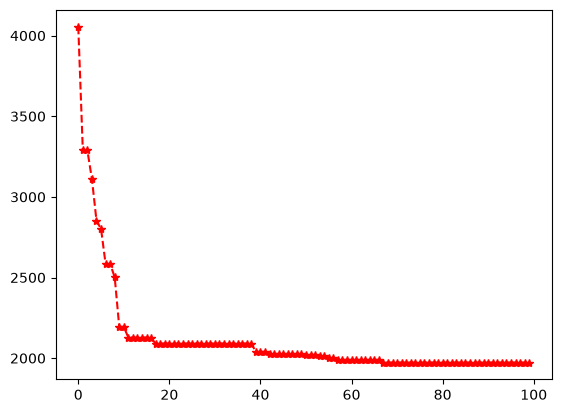

In [82]:
plt.plot(np.arange(100),costes_mejores,'r--*')